# Introducción a Tensorflow 2


In [11]:
import tensorflow as tf
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import time
import pandas as pd


print(tf.__version__)

2.20.0


In [12]:
semilla = 42
np.random.seed(semilla)
tf.random.set_seed(semilla)
random.seed(semilla)

## Conjunto de datos
Para comenzar, utilizaremos un clásico conjunto de datos denominado [MNIST](http://yann.lecun.com/exdb/mnist/), formado por un conjunto de imágenes de dígitos manuscritos
![images](https://storage.googleapis.com/tfds-data/visualization/fig/mnist-3.0.1.png)

In [14]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

El conjunto de entrenamiento está formado por 60.000 imágenes de 28x28, mientras que el de test lo forman 10.000 imágenes. El problema de clasificación consiste en distinguir entre los 10 dígitos diferentes

In [15]:
print("Datos de entrenamiento", x_train.shape)
print("Datos de test", x_test.shape)
print("Primeros dígitos: ", y_train[:5])

Datos de entrenamiento (60000, 28, 28)
Datos de test (10000, 28, 28)
Primeros dígitos:  [5 0 4 1 9]


## Pre-procesamiento
Como suele ser habitual, es conveniente realizar algún tipo de procesamiento antes de que los datos sean tratados por el modelo. En este caso, haremos un pequeño procesamiento que consiste en escalar los valores entre 0 y 1. Para ello, bastará con dividir por 255, ya que cada pixel de las imágenes de entrada viene representado por un entero entre 0 y 255 (8 bits) indicando su tonalidad de gris.

In [16]:
x_train = x_train / 255.0
x_test = x_test / 255.0
x_train.dtype

dtype('float64')

## Modelo
Para crear un modelo, primero tenemos que definir la arquitectura neuronal. El caso más sencillo es definir una estructura secuencial de capas, donde la primera actúa de capa de entrada y la última de salida del modelo. Cada capa tendrá una serie de parámetros dependiendo del tipo, habitualmente habrá que especificar el tamaño (número de neuronas), función de activación, etc.

In [17]:
model = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(28,28)),
  tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dense(10, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


## Entrenamiento
Antes de entrenar, hay que compilar el modelo indicando:
- La **regla de aprendizaje** (*optimizer*) que define el algoritmo para actualizar los pesos sinápticos de la red
- La **función objetivo** o de pérdida (*loss*), que es optimizada por la regla de aprendizaje
- La **métrica** o medida de evaluación (*metrics*) utilizada para evaluar el modelo entrenado

In [18]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

Tras compilar el modelo, el entrenamiento se define mediante los siguientes parámetros:
- **Épocas** (*epochs*). Número de veces que se le muestra el conjunto de entrenamiento al modelo
- Tamaño de **lote** (*batch_size*). Número de instancias o patrones que se muestran al modelo para actualizar los pesos sinápticos
- Conjunto de **validación** (*validation_spli*). Datos utilizados para medir el rendimiento durante el entrenamiento

En este caso, se ha optado por los valores por defecto

In [19]:
h=model.fit(x_train, y_train, epochs=5)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9276 - loss: 0.2530
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9669 - loss: 0.1113
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9774 - loss: 0.0754
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9834 - loss: 0.0549
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9881 - loss: 0.0412


## Evaluación
Una vez entrenada la red neuronal, prodremos obtener las medidas de rendimiento espcificadas en la etapa anterior, tanto para el conjunto de entrenamiento como para el conjunto de test

In [21]:
model.evaluate(x_train, y_train)
model.evaluate(x_test, y_test)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9893 - loss: 0.0350
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9753 - loss: 0.0788


[0.07876521348953247, 0.9753000140190125]

## Matriz de confusion para el ejemplo

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


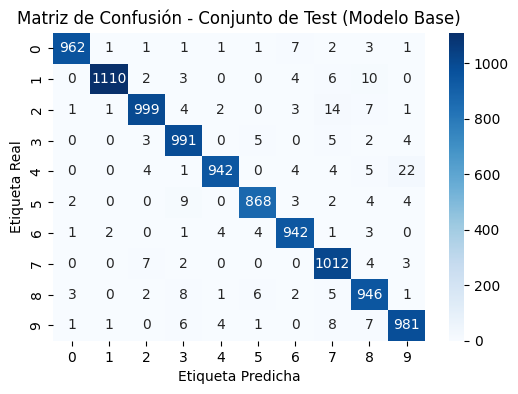

Número total de errores en test: 247 de 10000 imágenes


In [22]:
# Generar las predicciones para el conjunto de test
y_pred_prob = model.predict(x_test)

y_pred = np.argmax(y_pred_prob, axis=1)

# Matriz de confusión
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Etiqueta Predicha')
plt.ylabel('Etiqueta Real')
plt.title('Matriz de Confusión - Conjunto de Test (Modelo Base)')
plt.show()

# Total de errores en test
errores_test = np.sum(y_pred != y_test)
print(f"Número total de errores en test: {errores_test} de {len(y_test)} imágenes")

In [23]:
# Función para entrenar y evaluar el modelo con distintos parámetros

def entrenar_evaluar(neuronas=128, epocas=5, batch_size=32, optimizador='adam', val_split=0.0):
    model = tf.keras.models.Sequential([
        tf.keras.layers.Flatten(input_shape=(28, 28)),
        tf.keras.layers.Dense(neuronas, activation='relu'),
        tf.keras.layers.Dense(10, activation='softmax')
    ])

    model.compile(optimizer=optimizador,
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

    inicio = time.time()
    model.fit(x_train, y_train, epochs=epocas, batch_size=batch_size, validation_split=val_split, verbose=0)
    fin = time.time()

    tiempo_total = fin - inicio
    loss, accuracy = model.evaluate(x_test, y_test, verbose=0)

    y_pred = np.argmax(model.predict(x_test, verbose=0), axis=1)
    errores = np.sum(y_pred != y_test)

    resultados = {
        'neuronas': neuronas,
        'epocas': epocas,
        'batch_size': batch_size,
        'optimizador': optimizador,
        'val_split': val_split,
        'tiempo_s': round(tiempo_total, 2),
        'accuracy': round(accuracy, 4),
        'errores': errores
    }

    return resultados, model


# Lista para guardar los resultados de cada configuracion
resultados_globales = []

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


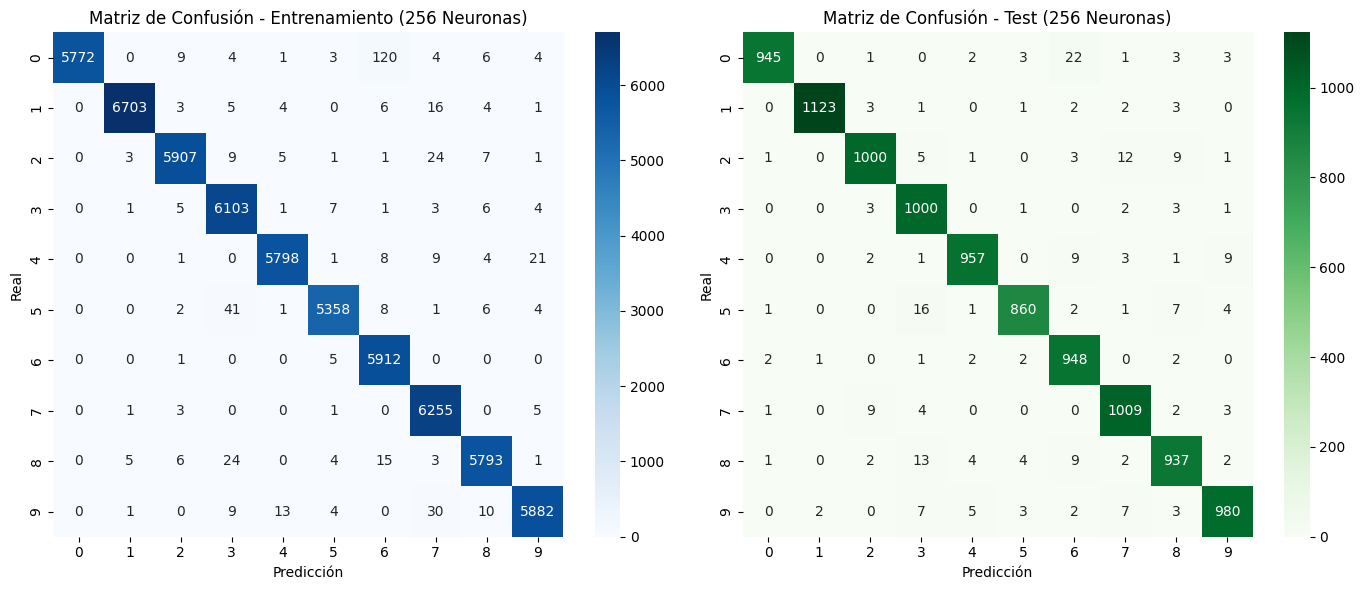

Tiempo de entrenamiento: 43.66 s
Accuracy: 0.9759
Errores: 241


In [24]:
# Entrenamiento aumentando las neuronas 128 -> 256

metricas_masneuronas, modelo_masneuronas = entrenar_evaluar(neuronas=256)

resultados_globales.append(metricas_masneuronas)

y_pred_train_masneuronas = np.argmax(modelo_masneuronas.predict(x_train, verbose=0), axis=1)
y_pred_test_masneuronas = np.argmax(modelo_masneuronas.predict(x_test, verbose=0), axis=1)

cm_train_masneuronas = confusion_matrix(y_train, y_pred_train_masneuronas)
cm_test_masneuronas = confusion_matrix(y_test, y_pred_test_masneuronas)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.heatmap(cm_train_masneuronas, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Matriz de Confusión - Entrenamiento (256 Neuronas)')
axes[0].set_xlabel('Predicción')
axes[0].set_ylabel('Real')

sns.heatmap(cm_test_masneuronas, annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title('Matriz de Confusión - Test (256 Neuronas)')
axes[1].set_xlabel('Predicción')
axes[1].set_ylabel('Real')

plt.tight_layout()
plt.show()

print(f"Tiempo de entrenamiento: {metricas_masneuronas['tiempo_s']} s")
print(f"Accuracy: {metricas_masneuronas['accuracy']}")
print(f"Errores: {metricas_masneuronas['errores']}")

Podemos observar que aumentar el número de neuronas, en este caso, no ayuda a mejorar el entrenamiento del modelo, pues comete más o menos los mismos errores que el original, pero sí que supone más tiempo en dicho entrenamiento. Por tanto, al no haber ninguna mejora evidente aumentando el número de neuronas, no parece ser lo más recomendable.

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


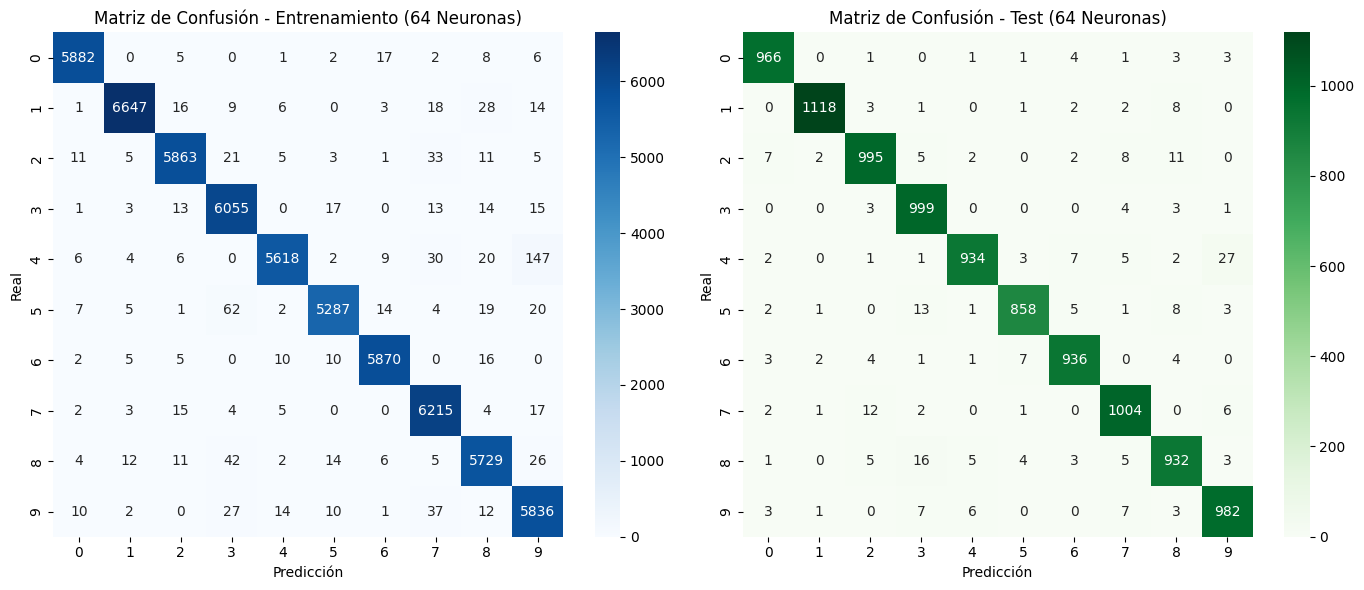

Tiempo de entrenamiento: 23.59 s
Accuracy: 0.9724
Errores en test: 276


In [25]:
# Entrenamiento disminuyendo las neuronas: 128 -> 64

metricas_menosneuronas, modelo_menosneuronas = entrenar_evaluar(neuronas=64)

resultados_globales.append(metricas_menosneuronas)

y_pred_train_menosneuronas = np.argmax(modelo_menosneuronas.predict(x_train, verbose=0), axis=1)
y_pred_test_menosneuronas = np.argmax(modelo_menosneuronas.predict(x_test, verbose=0), axis=1)

cm_train_menosneuronas = confusion_matrix(y_train, y_pred_train_menosneuronas)
cm_test_menosneuronas = confusion_matrix(y_test, y_pred_test_menosneuronas)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.heatmap(cm_train_menosneuronas, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Matriz de Confusión - Entrenamiento (64 Neuronas)')
axes[0].set_xlabel('Predicción')
axes[0].set_ylabel('Real')

sns.heatmap(cm_test_menosneuronas, annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title('Matriz de Confusión - Test (64 Neuronas)')
axes[1].set_xlabel('Predicción')
axes[1].set_ylabel('Real')

plt.tight_layout()
plt.show()

print(f"Tiempo de entrenamiento: {metricas_menosneuronas['tiempo_s']} s")
print(f"Accuracy: {metricas_menosneuronas['accuracy']}")
print(f"Errores en test: {metricas_menosneuronas['errores']}")

Parece que disminuir el número de neuronas ha sido un paso en la dirección correcta, ya que se ha disminuido en unos 15 segundos el tiempo que ha tardado el modelo original, sin sacrificar accuracy, el número de errores sigue siendo ínfimo en relación a la cantidad de pruebas y se puede decir que el modelo generaliza bien. Por tanto, en adelante entrenaremos los modelos con 64 neuronas.

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


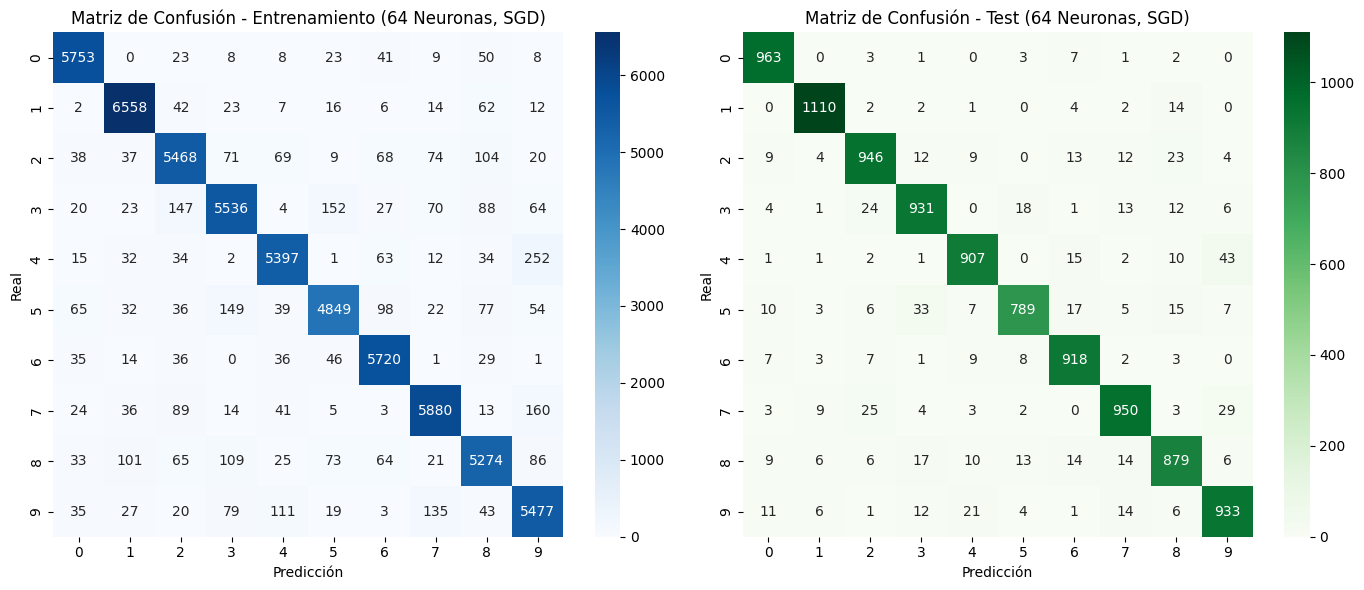

Tiempo de entrenamiento: 19.88 s
Accuracy: 0.9326
Errores en test: 674


In [26]:
# Entrenamiento cambiando el optimizador: Adam -> SGD

metricas_sgd_64, modelo_sgd_64 = entrenar_evaluar(neuronas=64, optimizador='sgd')

resultados_globales.append(metricas_sgd_64)

y_pred_train_sgd_64 = np.argmax(modelo_sgd_64.predict(x_train, verbose=0), axis=1)
y_pred_test_sgd_64 = np.argmax(modelo_sgd_64.predict(x_test, verbose=0), axis=1)

cm_train_sgd_64 = confusion_matrix(y_train, y_pred_train_sgd_64)
cm_test_sgd_64 = confusion_matrix(y_test, y_pred_test_sgd_64)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.heatmap(cm_train_sgd_64, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Matriz de Confusión - Entrenamiento (64 Neuronas, SGD)')
axes[0].set_xlabel('Predicción')
axes[0].set_ylabel('Real')

sns.heatmap(cm_test_sgd_64, annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title('Matriz de Confusión - Test (64 Neuronas, SGD)')
axes[1].set_xlabel('Predicción')
axes[1].set_ylabel('Real')

plt.tight_layout()
plt.show()


print(f"Tiempo de entrenamiento: {metricas_sgd_64['tiempo_s']} s")
print(f"Accuracy: {metricas_sgd_64['accuracy']}")
print(f"Errores en test: {metricas_sgd_64['errores']}")

En este caso, al cambiar el optimizador de Adam a SGD, no se observa un cambio significativo en cuanto al tiempo; no obstante el número de errores se ha disparado, y hay un notable descenso en el Accuracy. El modelo se equivoca mucho más, por lo que considero más conveniente mantener el optimizador Adam.

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


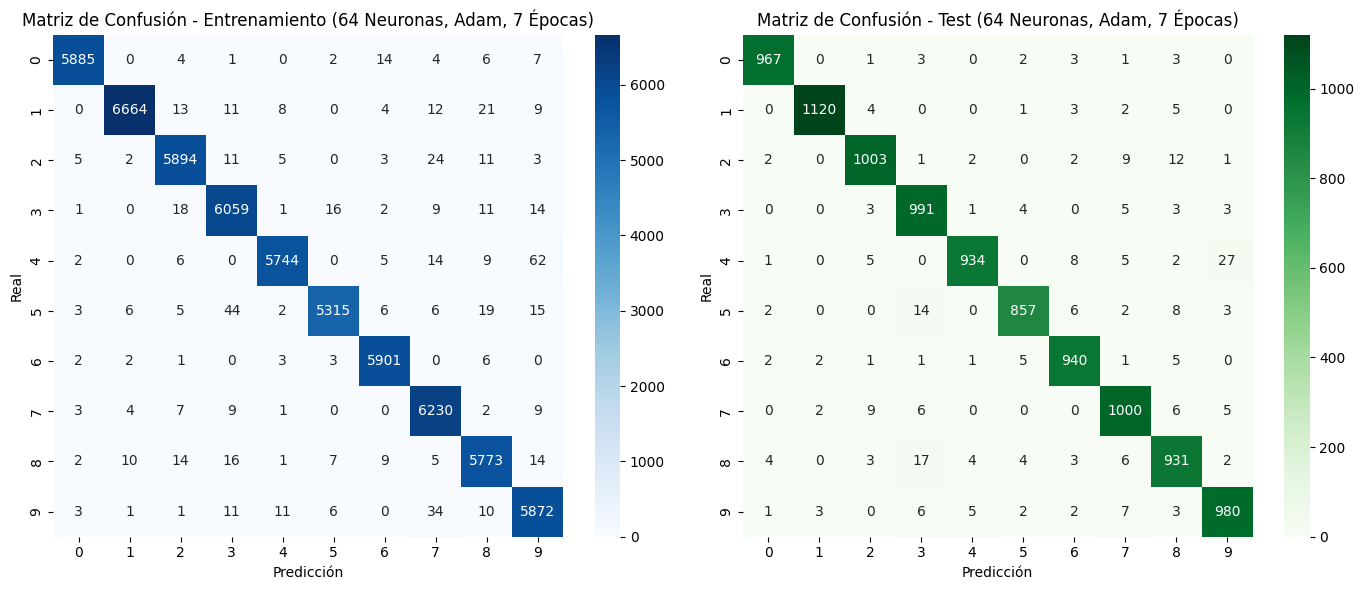

Tiempo de entrenamiento: 33.49 s
Accuracy: 0.9723
Errores en test: 277


In [27]:
# Entrenamiento aumentando las épocas: 5 -> 7

metricas_64neu_7ep, modelo_64neu_7ep = entrenar_evaluar(neuronas=64, epocas=7)

resultados_globales.append(metricas_64neu_7ep)

y_pred_train_64neu_7ep = np.argmax(modelo_64neu_7ep.predict(x_train, verbose=0), axis=1)
y_pred_test_64neu_7ep = np.argmax(modelo_64neu_7ep.predict(x_test, verbose=0), axis=1)

cm_train_64neu_7ep = confusion_matrix(y_train, y_pred_train_64neu_7ep)
cm_test_64neu_7ep = confusion_matrix(y_test, y_pred_test_64neu_7ep)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.heatmap(cm_train_64neu_7ep, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Matriz de Confusión - Entrenamiento (64 Neuronas, Adam, 7 Épocas)')
axes[0].set_xlabel('Predicción')
axes[0].set_ylabel('Real')

sns.heatmap(cm_test_64neu_7ep, annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title('Matriz de Confusión - Test (64 Neuronas, Adam, 7 Épocas)')
axes[1].set_xlabel('Predicción')
axes[1].set_ylabel('Real')

plt.tight_layout()
plt.show()

print(f"Tiempo de entrenamiento: {metricas_64neu_7ep['tiempo_s']} s")
print(f"Accuracy: {metricas_64neu_7ep['accuracy']}")
print(f"Errores en test: {metricas_64neu_7ep['errores']}")

Al aumentar el número de épocas de entrenamiento para el modelo, hemos obtenido un Accuracy prácticamente igual que el mejor que ya tenemos, a costa de tardar más. Teniendo en cuenta que ya nos estamos moviendo en unos rangos de Accuracy muy buenos, creo que merece más la pena priorizar ahora la velocidad por encima.

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


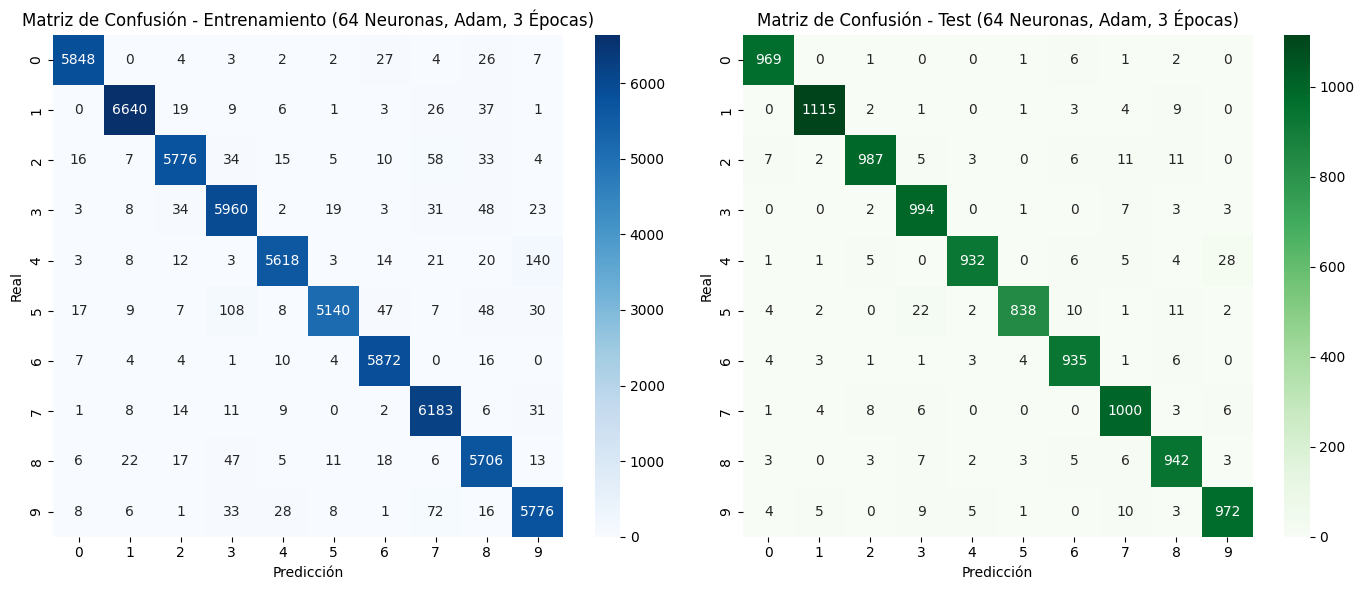

Tiempo de entrenamiento: 15.17 s
Accuracy: 0.9684
Errores en test: 316


In [28]:
# Entrenamiento disminuyendo las épocas: 5 -> 3

metricas_64neu_3ep, modelo_64neu_3ep = entrenar_evaluar(neuronas=64, epocas=3)

resultados_globales.append(metricas_64neu_3ep)

y_pred_train_64neu_3ep = np.argmax(modelo_64neu_3ep.predict(x_train, verbose=0), axis=1)
y_pred_test_64neu_3ep = np.argmax(modelo_64neu_3ep.predict(x_test, verbose=0), axis=1)

cm_train_64neu_3ep = confusion_matrix(y_train, y_pred_train_64neu_3ep)
cm_test_64neu_3ep = confusion_matrix(y_test, y_pred_test_64neu_3ep)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.heatmap(cm_train_64neu_3ep, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Matriz de Confusión - Entrenamiento (64 Neuronas, Adam, 3 Épocas)')
axes[0].set_xlabel('Predicción')
axes[0].set_ylabel('Real')

sns.heatmap(cm_test_64neu_3ep, annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title('Matriz de Confusión - Test (64 Neuronas, Adam, 3 Épocas)')
axes[1].set_xlabel('Predicción')
axes[1].set_ylabel('Real')

plt.tight_layout()
plt.show()

print(f"Tiempo de entrenamiento: {metricas_64neu_3ep['tiempo_s']} s")
print(f"Accuracy: {metricas_64neu_3ep['accuracy']}")
print(f"Errores en test: {metricas_64neu_3ep['errores']}")

Al disminuir las épocas a 3, hemos obtenido un accuracy prácticamente igual al mejor que hemos obtenido (menos de un 1% peor), y además el modelo ha ganado mucho en velocidad, tardando casi 10 segundos menos en finalizar su entrenamiento, lo que en este problema concreto es una mejora en tiempo muy notable.

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


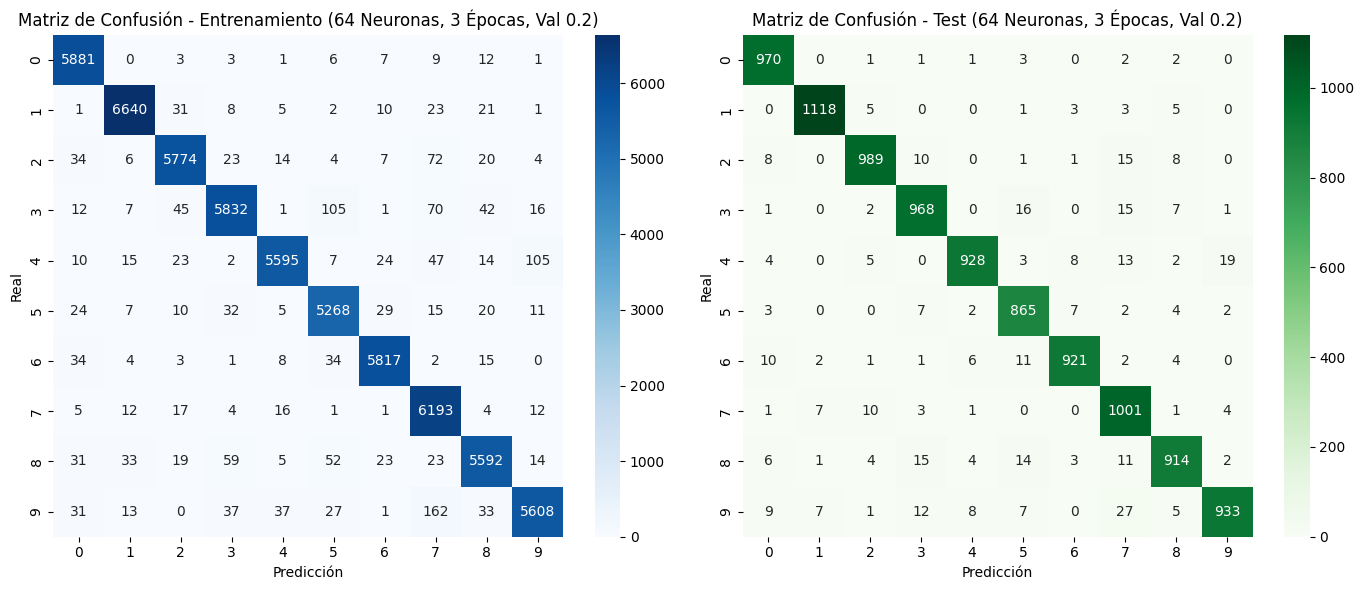

Tiempo de entrenamiento: 15.68 s
Accuracy: 0.9607
Errores en test: 393


In [29]:
metricas_64neu_3ep_val, modelo_64neu_3ep_val = entrenar_evaluar(neuronas=64, epocas=3, val_split=0.2)

resultados_globales.append(metricas_64neu_3ep_val)

y_pred_train_64neu_3ep_val = np.argmax(modelo_64neu_3ep_val.predict(x_train, verbose=0), axis=1)
y_pred_test_64neu_3ep_val = np.argmax(modelo_64neu_3ep_val.predict(x_test, verbose=0), axis=1)

cm_train_64neu_3ep_val = confusion_matrix(y_train, y_pred_train_64neu_3ep_val)
cm_test_64neu_3ep_val = confusion_matrix(y_test, y_pred_test_64neu_3ep_val)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.heatmap(cm_train_64neu_3ep_val, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Matriz de Confusión - Entrenamiento (64 Neuronas, 3 Épocas, Val 0.2)')
axes[0].set_xlabel('Predicción')
axes[0].set_ylabel('Real')

sns.heatmap(cm_test_64neu_3ep_val, annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title('Matriz de Confusión - Test (64 Neuronas, 3 Épocas, Val 0.2)')
axes[1].set_xlabel('Predicción')
axes[1].set_ylabel('Real')

plt.tight_layout()
plt.show()

print(f"Tiempo de entrenamiento: {metricas_64neu_3ep_val['tiempo_s']} s")
print(f"Accuracy: {metricas_64neu_3ep_val['accuracy']}")
print(f"Errores en test: {metricas_64neu_3ep_val['errores']}")

En este caso, observamos que hay una muy pequeña disminución del accuracy (menos de un 1%) y un tiempo prácticamente igual al mejor que hemos obtenido, al utilizar un 20% de conjunto de validación para el entrenamiento del modelo, esto es un resultado muy positivo, no solo por la mejora general en los resultados, sino también porque el hecho de que haya un conjunto de validación fomenta mucho la capacidad de generalización del modelo en el caso hipotético de que le llegaran ejemplos nuevos.

In [30]:

df_resultados = pd.DataFrame(resultados_globales)
display(df_resultados)

modelo_64neu_3ep_val.save('mejor_modelo_mnist.keras')
print("Modelo guardado exitosamente como 'mejor_modelo_mnist.keras'")

,neuronas,epocas,batch_size,optimizador,val_split,tiempo_s,accuracy,errores
0,256,5,32,adam,0.0,43.66,0.9759,241
1,64,5,32,adam,0.0,23.59,0.9724,276
2,64,5,32,sgd,0.0,19.88,0.9326,674
3,64,7,32,adam,0.0,33.49,0.9723,277
4,64,3,32,adam,0.0,15.17,0.9684,316
5,64,3,32,adam,0.2,15.68,0.9607,393


Modelo guardado exitosamente como 'mejor_modelo_mnist.keras'


# CONCLUSIÓN:
La configuración óptima elegida es la de 64 neuronas, 3 épocas, optimizador Adam y un 0.2 de validación.

El criterio principal ha sido buscar el equilibrio más eficiente entre el tiempo de ejecución y el rendimiento general de la red.

Hemos comprobado que reducir el número de parámetros y de pasadas recorta bastante el tiempo de entrenamiento, sacrificando una cantidad mínima de accuracy.

A su vez, la inclusión del conjunto de validación ha sido clave para garantizar que el modelo no se sobreajusta y mantiene una buena capacidad de generalización.

En definitiva, compensa mucho más quedarse con un modelo ligero, rápido y robusto que gastar tiempo computacional extra solo para ganar unos pocos aciertos en test.